# **Statistical Learning on CASdatasets-$\texttt{euMTPL}$**

### **Setup and helper functions**
The data set has 2.37 million rows. To keep memory low, the Poisson GLM on the full training set is fitted by a small chunked IRLS routine instead of `statsmodels.GLM`. The GVIF follows `car::vif` in R, i.e. it uses the correlation matrix of the coefficient estimates.

In [ ]:
import urllib.request
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
import statsmodels.api as sm
from IPython.display import display
from scipy import stats

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

CATEGORICAL = ["fuel_type", "vehicle_use", "vehicle_category", "gender"]


def design_matrix(data, terms):
    """Treatment-coded model matrix (first level = reference, as in R) and term -> columns map."""
    parts, groups = [], {}
    for t in terms:
        if t in CATEGORICAL or str(data[t].dtype) == "category":
            block = pd.get_dummies(data[t], prefix=t, drop_first=True, dtype=float)
        else:
            block = data[[t]].astype(float)
        groups[t] = list(block.columns)
        parts.append(block)
    X = pd.concat(parts, axis=1)
    X.insert(0, "Intercept", 1.0)
    return X, groups


@dataclass
class PoissonFit:
    params: pd.Series
    mu: np.ndarray
    cov_unscaled: pd.DataFrame      # (X'WX)^-1
    deviance: float
    null_deviance: float
    df_resid: int
    df_null: int


def _poisson_deviance(y, mu):
    with np.errstate(divide="ignore", invalid="ignore"):
        term = np.where(y > 0, y * np.log(y / mu), 0.0)
    return 2.0 * float(np.sum(term - (y - mu)))


def poisson_glm(data, terms, chunk=200_000, tol=1e-8, max_iter=30):
    """Poisson GLM, log link, offset(log(exposure)), fitted by chunked IRLS."""
    Xdf, groups = design_matrix(data, terms)
    cols = list(Xdf.columns)
    X = Xdf.to_numpy(dtype=np.float64)
    del Xdf
    y = data["num"].to_numpy(dtype=float)
    offset = np.log(data["exposure"].to_numpy(dtype=float))
    n, p = X.shape
    mu0 = y.sum() / np.exp(offset).sum() * np.exp(offset)     # intercept-only fit
    mu, eta, dev_old = mu0.copy(), np.log(mu0), _poisson_deviance(y, mu0)
    for _ in range(max_iter):
        xtwx, xtwz = np.zeros((p, p)), np.zeros(p)
        for s in range(0, n, chunk):
            sl = slice(s, s + chunk)
            w = mu[sl]
            z = (eta[sl] - offset[sl]) + (y[sl] - w) / w        # working response
            xtwx += X[sl].T @ (X[sl] * w[:, None])
            xtwz += X[sl].T @ (w * z)
        beta = np.linalg.solve(xtwx, xtwz)
        for s in range(0, n, chunk):
            sl = slice(s, s + chunk)
            eta[sl] = X[sl] @ beta + offset[sl]
        mu = np.exp(eta)
        dev = _poisson_deviance(y, mu)
        if abs(dev - dev_old) / (abs(dev) + 0.1) < tol:
            break
        dev_old = dev
    fit = PoissonFit(pd.Series(beta, index=cols), mu,
                     pd.DataFrame(np.linalg.inv(xtwx), index=cols, columns=cols),
                     dev, _poisson_deviance(y, mu0), n - p, n - 1)
    return fit, X, groups


def hat_values(X, fit, chunk=200_000):
    """Leverages h_i = w_i x_i' (X'WX)^-1 x_i with w = mu."""
    h = np.empty(X.shape[0])
    cov = fit.cov_unscaled.to_numpy()
    for s in range(0, X.shape[0], chunk):
        sl = slice(s, s + chunk)
        h[sl] = fit.mu[sl] * np.einsum("ij,jk,ik->i", X[sl], cov, X[sl], optimize=True)
    return h


def vif(cov, groups):
    """Generalized VIF (Fox & Monette), like car::vif: built from cov2cor(vcov(model))."""
    keep = [c for c in cov.columns if c != "Intercept"]
    c = cov.loc[keep, keep].to_numpy()
    d = np.sqrt(np.diag(c))
    corr = pd.DataFrame(c / np.outer(d, d), index=keep, columns=keep)
    det_all = np.linalg.det(corr.to_numpy())
    rows = []
    for term, tc in groups.items():
        rest = [k for k in keep if k not in tc]
        g = np.linalg.det(corr.loc[tc, tc].to_numpy()) * np.linalg.det(corr.loc[rest, rest].to_numpy()) / det_all
        rows.append((term, g, len(tc), g ** (1 / (2 * len(tc)))))
    return pd.DataFrame(rows, columns=["term", "GVIF", "Df", "GVIF^(1/(2*Df))"]).set_index("term")

## **Modeling Claim Count $N$**
In the following `code` cells, we load the data, compress the data frame, leaving only the explanatory risk factors and total claim counts for each risk profile. We then fit the Poisson GLM with and without `year` as a risk factor. The **likelihood-ratio test** finds that `year` is a statistically significant risk factor ($\Lambda = 746.07$, $q=2$, $p \approx 9.830848\times 10^{-163}$). 

Further, we compute the ratio of expected claim counts across years holding other risk factors fixed. With `year = 7` as the baseline, years 8 and 9 have expected claim counts approximately 1.09 and 1.17 times that of year 7, respectively.

Finally, we split the data frame into training (years 7–8) and testing (year 9) datasets, with `year` encoded as numeric so the fitted  trend can be extrapolated to `year = 9`.

In [ ]:
URL = "https://raw.githubusercontent.com/dutangc/CASdatasets/master/data/euMTPL.rda"
rda = Path("euMTPL.rda")
if not rda.exists():
    urllib.request.urlretrieve(URL, rda)

df_eu = pyreadr.read_r(str(rda))["euMTPL"]
df_eu["year"] = df_eu["year"].astype(int).astype("category")      # year as a factor
df_eu["num_fcd"] = df_eu["num_fcg"]
df_eu["cost_fcd"] = df_eu["cost_fcg"]
df_eu["num"] = df_eu["num_fcd"] + df_eu["num_cd"]
df_eu["cost"] = df_eu["cost_fcd"] + df_eu["cost_cd"]
df_eu = df_eu[["policy_id", "fuel_type", "year", "vehicle_category", "vehicle_use",
               "horsepower", "gender", "age", "exposure", "num", "cost"]].copy()
for col in ["fuel_type", "vehicle_category", "vehicle_use", "gender"]:
    df_eu[col] = df_eu[col].astype(str).astype("category")

In [ ]:
print(df_eu.shape)
display(df_eu.head())
display(df_eu.describe(include="all").T)

(2373197, 11)


,policy_id,fuel_type,year,vehicle_category,vehicle_use,horsepower,gender,age,exposure,num,cost
0,1,B,7,1,1,14,M,77,0.487671,0,0.0
1,2,B,7,1,1,12,M,40,0.019178,0,0.0
2,4,B,7,1,1,14,M,75,0.032877,0,0.0
3,5,B,7,1,1,13,M,48,0.043836,0,0.0
4,6,B,7,1,1,12,F,54,0.046575,0,0.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
policy_id,2373197.0,NaN,NaN,NaN,1290069.897944,750483.235448,1.0,641820.0,1280437.0,1939574.0,2595214.0
fuel_type,2373197,8,B,1382612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,2373197.0,3.0,9.0,794898.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_category,2373197,2,1,2360481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_use,2373197,5,1,2359462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
horsepower,2373197.0,NaN,NaN,NaN,16.52047,4.560982,0.0,14.0,16.0,19.0,999.0
gender,2373197,2,M,1479849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2373197.0,NaN,NaN,NaN,48.174671,14.508979,18.0,37.0,46.0,59.0,109.0
exposure,2373197.0,NaN,NaN,NaN,0.62659,0.347323,0.001,0.300546,0.682192,1.0,1.0
num,2373197.0,NaN,NaN,NaN,0.077326,0.30599,0.0,0.0,0.0,0.0,21.0


In [ ]:
# Compress: one row per risk profile (sum of claim counts and of exposure).
# For a Poisson GLM with offset this leaves coefficients and deviance differences unchanged.
risk = ["fuel_type", "year", "vehicle_category", "vehicle_use", "horsepower", "gender", "age"]
df_comp = (df_eu.groupby(risk, observed=True, as_index=False)
                .agg(num=("num", "sum"), exposure=("exposure", "sum")))
print(df_comp.shape)

def poisson_small(data, terms):
    X, groups = design_matrix(data, terms)
    res = sm.GLM(data["num"], X, family=sm.families.Poisson(), offset=np.log(data["exposure"])).fit()
    return res

base = ["fuel_type", "vehicle_category", "vehicle_use", "horsepower", "gender", "age"]
poisson_fit_full = poisson_small(df_comp, base + ["year"])
poisson_fit_reduced = poisson_small(df_comp, base)

(45908, 9)


In [ ]:
# Likelihood-ratio test: with vs. without year (anova(..., test = "LRT") in R)
lam = poisson_fit_reduced.deviance - poisson_fit_full.deviance
q = int(poisson_fit_reduced.df_resid - poisson_fit_full.df_resid)
pd.DataFrame({"Resid. Df": [poisson_fit_reduced.df_resid, poisson_fit_full.df_resid],
              "Resid. Dev": [poisson_fit_reduced.deviance, poisson_fit_full.deviance],
              "Df": [np.nan, q], "Deviance": [np.nan, lam],
              "Pr(>Chi)": [np.nan, stats.chi2.sf(lam, q)]}, index=[1, 2])

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
1,45892,44143.171967,NaN,NaN,NaN
2,45890,43397.100277,2.0,746.07169,9.830848e-163


In [ ]:
# Ratio of expected claim counts across years, other risk factors fixed (year 7 = baseline).
year_coefs = poisson_fit_full.params.filter(like="year")
np.exp(year_coefs)

year_8    1.094518
year_9    1.169947
dtype: float64

In [ ]:
df_train = df_eu[df_eu["year"].isin([7, 8])].copy()
df_test = df_eu[df_eu["year"] == 9].copy()
print(len(df_train), len(df_test))

1578299 794898


### **Fitting Poisson GLM to the training dataset**
#### **Preliminary Diagnostics & Covariate Screening**
We first check if there is correlation between continuous risk factors `horsepower` and `age`. Then, we check the collinearity via VIF and GVIF after fitting the full model. 

In [ ]:
df_train["age"].corr(df_train["horsepower"])

np.float64(-0.06689501622899581)

In [ ]:
# Convert year to a numeric linear trend
df_train["year"] = df_train["year"].astype(int)
df_test["year"] = df_test["year"].astype(int)

fit_count_train, X, groups = poisson_glm(
    df_train, ["fuel_type", "year", "vehicle_category", "vehicle_use", "horsepower", "gender", "age"])
fit_count_train.params

Intercept            -2.470227
fuel_type_D           0.260759
fuel_type_E           0.061786
fuel_type_G           0.266007
fuel_type_M           0.179877
fuel_type_P           0.296215
fuel_type_S           0.245377
fuel_type_T           0.218270
year                  0.090427
vehicle_category_8   -0.301166
vehicle_use_1        -0.187684
vehicle_use_26        0.639831
vehicle_use_4         0.092605
vehicle_use_5         0.728744
horsepower            0.004089
gender_M             -0.034573
age                  -0.006557
dtype: float64

In [ ]:
display(vif(fit_count_train.cov_unscaled, groups))
display(pd.crosstab(df_train["vehicle_category"], df_train["vehicle_use"]))
del X

,GVIF,Df,GVIF^(1/(2*Df))
term,,,
fuel_type,1.088014,7,1.006043
year,1.001289,1,1.000644
vehicle_category,215.952283,1,14.695315
vehicle_use,216.167778,4,1.958163
horsepower,1.026678,1,1.013251
gender,1.067581,1,1.033238
age,1.060263,1,1.029691


vehicle_use,0,1,26,4,5
vehicle_category,,,,,
1,0,1568588,276,79,328
8,9002,0,0,5,21


#### **Variable Selection**
Since the VIF of `vehicle_category` and `vehicle_use` are unusually high, we drop `vehicle_category` and fit the model again. This resolves the collinearity, and VIF's of all present factors are now roughly 1.

In [ ]:
fit_count_train_update, X, groups = poisson_glm(
    df_train, ["fuel_type", "year", "vehicle_use", "horsepower", "gender", "age"])
vif(fit_count_train_update.cov_unscaled, groups)

,GVIF,Df,GVIF^(1/(2*Df))
term,,,
fuel_type,1.088002,7,1.006043
year,1.001289,1,1.000644
vehicle_use,1.003781,4,1.000472
horsepower,1.026675,1,1.013250
gender,1.067575,1,1.033235
age,1.060263,1,1.029691


#### **Outliers and Influential Points**
We first compute the leverages, then the residual. 

In [ ]:
h = hat_values(X, fit_count_train_update)
p = X.shape[1]
n = len(df_train)
lev_thresh = 3 * (p / n)
high_leverage_idx = np.where(h > lev_thresh)[0]
len(high_leverage_idx)

42409

In [ ]:
y_tr = df_train["num"].to_numpy(dtype=float)
mu_tr = fit_count_train_update.mu
r_pearson = (y_tr - mu_tr) / np.sqrt(mu_tr) / np.sqrt(1 - h)     # studentised Pearson residuals
outlier_idx = np.where(np.abs(r_pearson) > 3)[0]
len(outlier_idx)

50823

### **Model Significance & Goodness-of-Fit Assessment**
The following `code` provide the results of **Likelihood-Ratio Test**, **Deviance Goodness-of-Fit Test** and **Pearson's Chi-Squared Test** respectively.

#### **Overall Model Significance (Likelihood-Ratio Test)**
$p$-value being essentialy $0$ shows that our risk factors actually have predictive power.

In [ ]:
fit = fit_count_train_update
dif_dev = fit.null_deviance - fit.deviance
dif_df = fit.df_null - fit.df_resid
p_val_lrt = stats.chi2.sf(dif_dev, dif_df)
print(dif_dev, dif_df, p_val_lrt)
print(fit.df_null)
print(fit.df_resid)

4148.619972800836 15 0.0
1578298
1578283


#### **Model Specification (Deviance Goodness-of-Fit Test)**
$p$-value being approximately 1 could suggest the Poisson GLM is well specified, but we treat this with caution — see the "Final Verdict" discussion below regarding the reliability of this test under sparse fitted means.

In [ ]:
dev = fit.deviance
df_res = fit.df_resid
p_val_gof = stats.chi2.sf(dev, df_res)
print(dev, p_val_gof)

610732.06967974 1.0


#### **Overdispersion (Pearson Chi-Squared Test)**
The large value of X2 shows that sum of squared standardised errors is large, and the estimate of the dispersion parameter (`est.phi = 1.27`) is the evidence of dispersion. 

In [ ]:
fit_val = mu_tr                                   # fitted values on the training data
X2 = np.sum((fit_val - y_tr) ** 2 / fit_val)      # sum of squared standardised errors
df_train_residual = fit.df_resid
p_val_X2 = stats.chi2.sf(X2, df_train_residual)
est_phi = X2 / df_train_residual                  # estimate of dispersion parameter
print(X2, p_val_X2, est_phi)

2010374.5403552107 0.0 1.2737731701825405


## **Modeling Claim Severity $Y_j$**
In the following `code` cells we first remove individuals with 0 claim. Then, we compute the average claim amounts for each individual. 

In [ ]:
df_sev = df_eu[df_eu["num"] > 0].copy()           # remove insureds with no claim
df_sev["sev"] = df_sev["cost"] / df_sev["num"]    # average claim amount
df_sev = df_sev[["policy_id", "fuel_type", "year", "vehicle_category", "vehicle_use",
                 "horsepower", "gender", "age", "num", "sev"]]
df_sev["year"] = df_sev["year"].astype(int)
df_train_sev = df_sev[df_sev["year"].isin([7, 8])].copy()
df_test_sev = df_sev[df_sev["year"] == 9].copy()
del df_eu, df_train, df_test, X
df_sev.head()

,policy_id,fuel_type,year,vehicle_category,vehicle_use,horsepower,gender,age,num,sev
40,44,B,7,1,1,12,F,31,1,1800.0
172,182,B,7,1,1,18,M,45,1,1800.0
186,196,B,7,1,1,18,F,74,1,1800.0
205,215,D,7,1,1,19,F,60,1,2000.0
381,396,B,7,1,1,15,M,60,1,2000.0


### **Fitting Gamma GLM**

In [ ]:
def gamma_glm(data, terms):
    Xg, groups = design_matrix(data, terms)
    res = sm.GLM(data["sev"], Xg, family=sm.families.Gamma(sm.families.links.Log()),
                 var_weights=data["num"]).fit(scale="X2")      # Pearson-based dispersion, as in R
    cov = pd.DataFrame(res.cov_params(), index=Xg.columns, columns=Xg.columns)
    return res, cov, groups

fit_sev_train, cov_sev, groups_sev = gamma_glm(
    df_train_sev, ["fuel_type", "year", "vehicle_use", "vehicle_category", "horsepower", "gender", "age"])
display(vif(cov_sev, groups_sev))
print(fit_sev_train.summary())

,GVIF,Df,GVIF^(1/(2*Df))
term,,,
fuel_type,1.197008,7,1.012927
year,1.001151,1,1.000575
vehicle_use,217.522474,4,1.959693
vehicle_category,217.088731,1,14.733931
horsepower,1.172956,1,1.083031
gender,1.064878,1,1.031929
age,1.043834,1,1.021682


                 Generalized Linear Model Regression Results                  
Dep. Variable:                    sev   No. Observations:               102672
Model:                            GLM   Df Residuals:                   102655
Model Family:                   Gamma   Df Model:                           16
Link Function:                    Log   Scale:                         0.37389
Method:                          IRLS   Log-Likelihood:            -8.3199e+05
Date:                Tue, 24 Nov 2026   Deviance:                       17584.
Time:                        11:09:42   Pearson chi2:                 3.84e+04
No. Iterations:                    20   Pseudo R-squ. (CS):            0.01410
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              8.1347      0

#### **Variable Selection**
As for the Claim count $N$, we also detect collinearity in `vehicle_use` and `vehicle_category`. By dropping `vehicle_category`, the collinearity is resolved.

In [ ]:
fit_sev_train_update, cov_sev, groups_sev = gamma_glm(
    df_train_sev, ["fuel_type", "year", "vehicle_use", "horsepower", "gender", "age"])
display(vif(cov_sev, groups_sev))
print(fit_sev_train_update.summary())

,GVIF,Df,GVIF^(1/(2*Df))
term,,,
fuel_type,1.196969,7,1.012925
year,1.001150,1,1.000575
vehicle_use,1.005796,4,1.000723
horsepower,1.172954,1,1.083030
gender,1.064867,1,1.031924
age,1.043822,1,1.021676


                 Generalized Linear Model Regression Results                  
Dep. Variable:                    sev   No. Observations:               102672
Model:                            GLM   Df Residuals:                   102656
Model Family:                   Gamma   Df Model:                           15
Link Function:                    Log   Scale:                         0.37389
Method:                          IRLS   Log-Likelihood:            -8.3199e+05
Date:                Tue, 24 Nov 2026   Deviance:                       17584.
Time:                        11:09:43   Pearson chi2:                 3.84e+04
No. Iterations:                    20   Pseudo R-squ. (CS):            0.01409
Covariance Type:            nonrobust                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          8.5368      0.038    227.

#### **Goodness-of-Fit Diagnostics**
We provide two QQ-plots to see if our model is well specified. 

0.37389497548802486


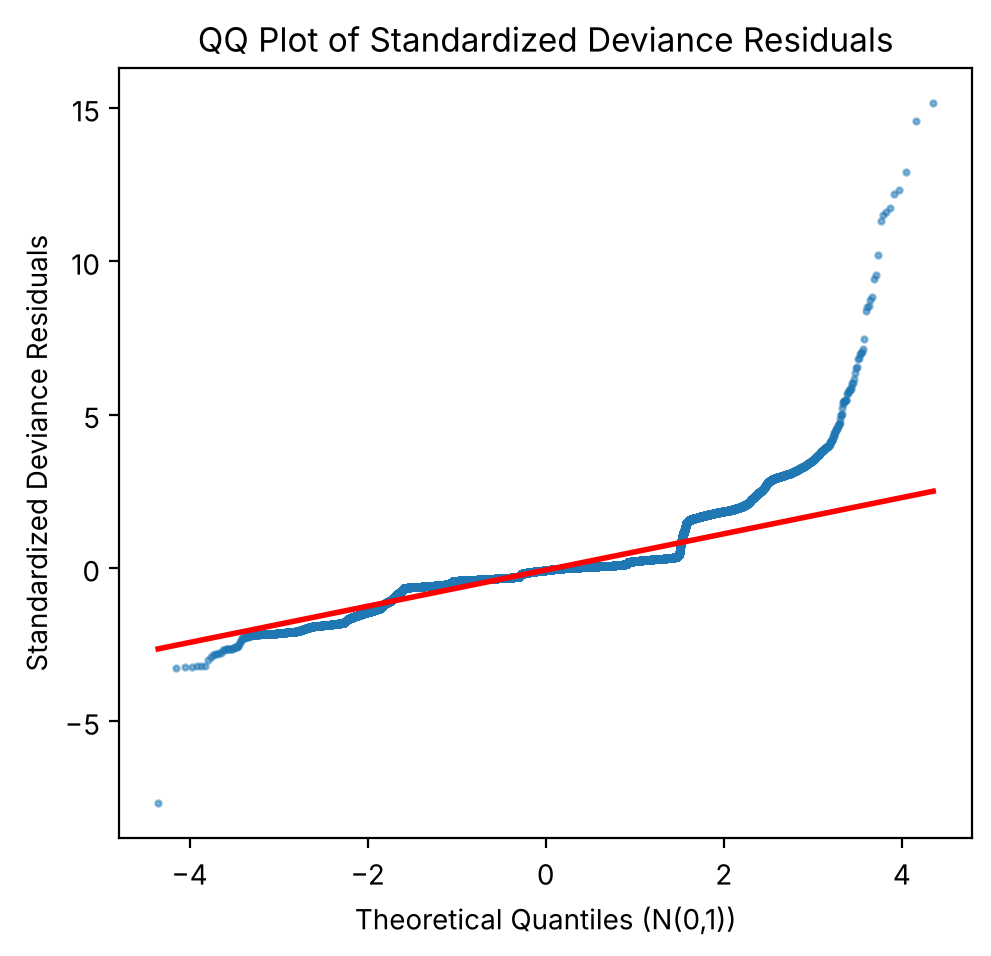

In [ ]:
phi_hat = fit_sev_train_update.scale
resid_dev = fit_sev_train_update.resid_deviance
resid_std = resid_dev / np.sqrt(phi_hat)
print(phi_hat)

fig, ax = plt.subplots(figsize=(5.5, 5))
(osm, osr), (slope, intercept, _) = stats.probplot(resid_std, dist="norm")
ax.scatter(osm, osr, s=4, alpha=0.5)
ax.plot(osm, slope * osm + intercept, color="red", lw=2)
ax.set(title="QQ Plot of Standardized Deviance Residuals",
       xlabel="Theoretical Quantiles (N(0,1))", ylabel="Standardized Deviance Residuals")
plt.show()

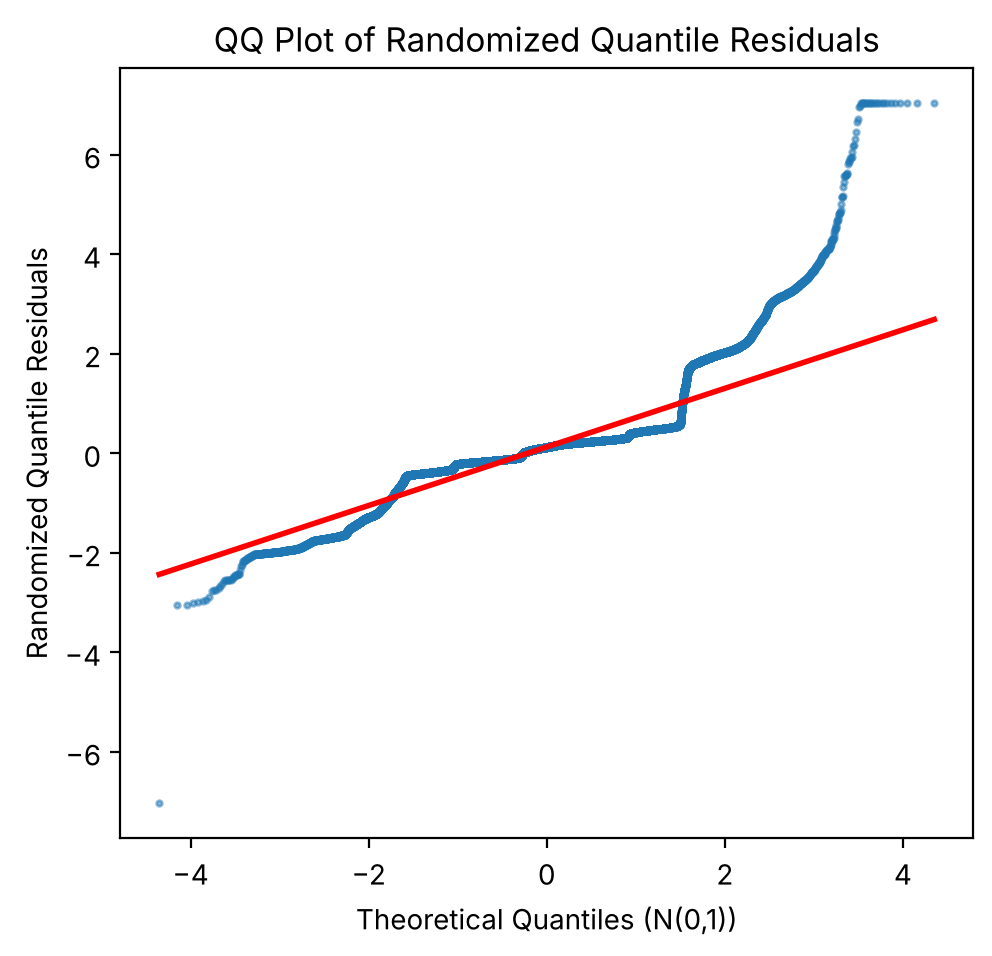

In [ ]:
# Randomized quantile residuals (Dunn & Smyth), like statmod::qresid.
# For a continuous Gamma response no randomization is needed: u = F(y), r = Phi^-1(u).
w = df_train_sev["num"].to_numpy()
mu = fit_sev_train_update.mu
y = df_train_sev["sev"].to_numpy()
u = stats.gamma.cdf(y, a=w / phi_hat, scale=mu * phi_hat / w)
qres = stats.norm.ppf(np.clip(u, 1e-12, 1 - 1e-12))

fig, ax = plt.subplots(figsize=(5.5, 5))
(osm, osr), (slope, intercept, _) = stats.probplot(qres, dist="norm")
ax.scatter(osm, osr, s=4, alpha=0.5)
ax.plot(osm, slope * osm + intercept, color="red", lw=2)
ax.set(title="QQ Plot of Randomized Quantile Residuals",
       xlabel="Theoretical Quantiles (N(0,1))", ylabel="Randomized Quantile Residuals")
plt.show()